# Task 6 (Advanced) – Data Science Business Insights Dashboard
**Internship:** Auspify Technologies – Data Science Program  
**Intern:** Shabbir Moomin (Colombo, Sri Lanka)  
**Dataset:** `Netflix_Cleaned.csv` (Task 1 output)

**Goal:** an end-to-end project combining analytics, machine learning and business insights.

**Workflow**
1. Perform complete data analysis
2. Develop predictive models
3. Create interactive visualizations (→ exported to the HTML dashboard)
4. Generate business recommendations
5. Present findings in a professional report (→ separate Word-style report document)

**Business framing:** imagine I'm an analyst advising Netflix's *content strategy* team. The data has **no viewing / revenue data**, so every recommendation is about *catalogue composition* (what is being added, where from, for whom), not about what viewers watch.

In [1]:
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RED, GREY = '#E50914', '#564d4d'
np.random.seed(42)

df = pd.read_csv('Netflix_Cleaned.csv', parse_dates=['date_added'])
print(df.shape)

(8786, 34)


## Step 1 – Perform complete data analysis

### 1.1 Headline numbers

In [2]:
kpi = {
    'titles': len(df),
    'movies_pct': (df['type'] == 'Movie').mean() * 100,
    'tv_pct': (df['type'] == 'TV Show').mean() * 100,
    'countries': df.loc[df['primary_country'] != 'Unknown', 'primary_country'].nunique(),
    'median_movie_min': df['duration_min'].median(),
    'tv_one_season_pct': (df['seasons'] == 1).sum() / df['seasons'].notna().sum() * 100,
    'added_within_1y_pct': (df['years_to_add'] <= 1).mean() * 100,
    'adult_pct': (df['audience'] == 'Adults').mean() * 100,
    'kids_pct': df['audience'].isin(['Kids', 'Older Kids']).mean() * 100,
    'us_pct': (df['primary_country'] == 'United States').mean() * 100,
}
print({k: round(v, 1) for k, v in kpi.items()})

{'titles': 8786, 'movies_pct': 69.7, 'tv_pct': 30.3, 'countries': 85, 'median_movie_min': 98.0, 'tv_one_season_pct': 67.2, 'added_within_1y_pct': 55.0, 'adult_pct': 45.6, 'kids_pct': 23.4, 'us_pct': 36.9}


### 1.2 How fast is the catalogue growing – and with what?

type        Movie  TV Show  Total  TV share %  YoY %
year_added                                          
2014           19        5     24        20.8    NaN
2015           56       26     82        31.7  241.7
2016          251      175    426        41.1  419.5
2017          836      349   1185        29.5  178.2
2018         1236      411   1647        25.0   39.0
2019         1422      591   2013        29.4   22.2
2020         1284      595   1879        31.7   -6.7
2021          993      505   1498        33.7  -20.3


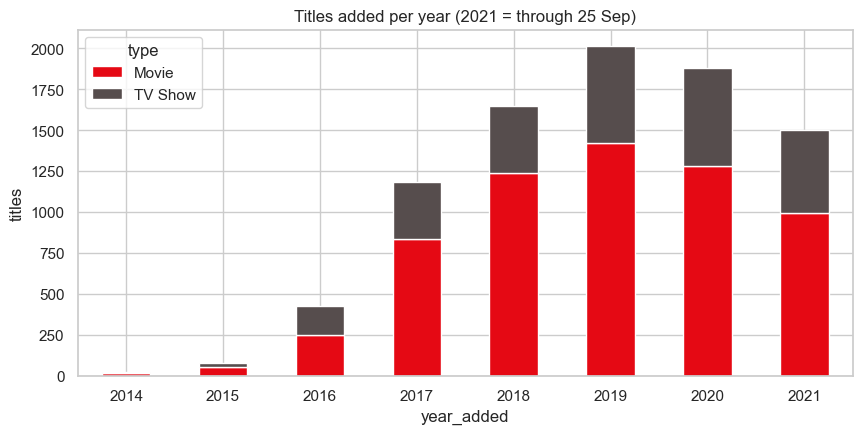

In [3]:
add = df[df['year_added'] >= 2014].groupby(['year_added', 'type']).size().unstack(fill_value=0)
add['Total'] = add.sum(axis=1)
add['TV share %'] = (add['TV Show'] / add['Total'] * 100).round(1)
add['YoY %'] = (add['Total'].pct_change() * 100).round(1)
print(add)
ax = add[['Movie', 'TV Show']].plot(kind='bar', stacked=True, color=[RED, GREY], figsize=(10, 4.5), rot=0)
ax.set_title('Titles added per year (2021 = through 25 Sep)'); ax.set_ylabel('titles'); plt.show()

### 1.3 Is the catalogue becoming more international?
(US share of titles with a known country, by year added.)

US share % by year added: {2014: 79.2, 2015: 63.0, 2016: 41.7, 2017: 34.7, 2018: 31.7, 2019: 39.1, 2020: 39.1, 2021: 41.5}
{'United States': 2047, 'India': 553, 'United Kingdom': 343, 'Pakistan': 270, 'Japan': 173, 'Canada': 144, 'South Korea': 134, 'France': 129}


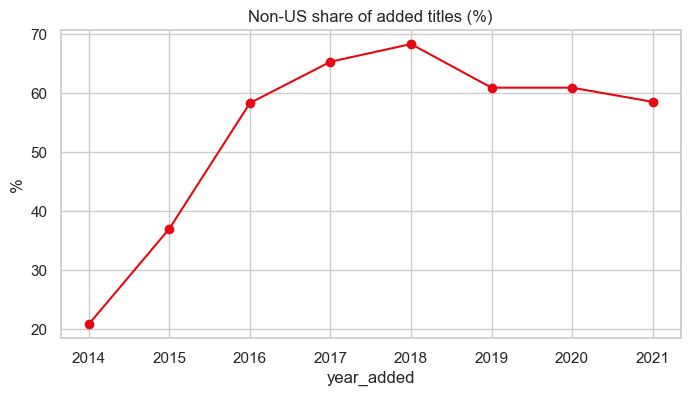

In [4]:
known = df[df['primary_country'] != 'Unknown'].copy()
known['is_us'] = known['primary_country'] == 'United States'
intl = known[known['year_added'] >= 2014].groupby('year_added')['is_us'].mean().mul(100).round(1)
print('US share % by year added:', intl.to_dict())

# non-US share excluding India/UK etc is not needed - just show the trend + top non-US countries added since 2019
recent = known[known['year_added'] >= 2019]
print(recent['primary_country'].value_counts().head(8).to_dict())
ax = (100 - intl).plot(marker='o', color=RED, figsize=(8, 4)); ax.set_title('Non-US share of added titles (%)'); ax.set_ylabel('%'); plt.show()

### 1.4 Country and genre momentum

Genre share change 2017 -> 2020 (percentage points), biggest risers:
{'Thrillers': 1.6, 'Action Adventure': 1.8, 'Horror': 2.0, 'Romantic': 2.4, 'Children Family': 2.5, 'Comedies': 8.7}
Biggest fallers:
{'Documentaries': -11.1, 'International': -5.3, 'Independent': -1.9, 'Crime': 0.1, 'Dramas': 1.6}


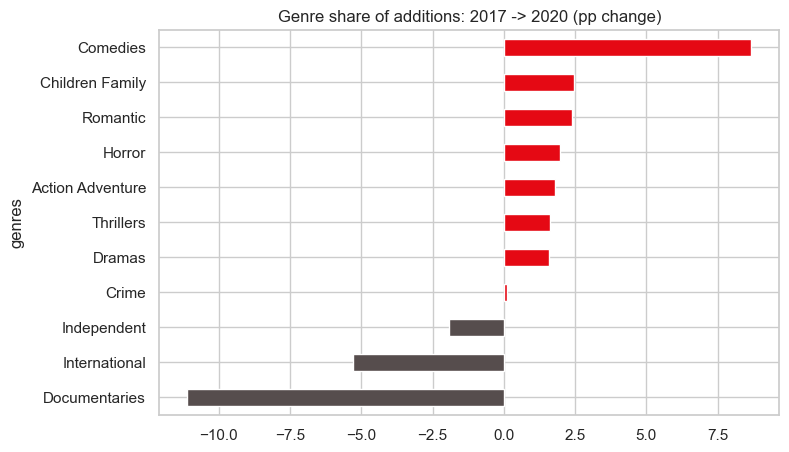

In [5]:
def norm_genre(g):
    g = re.sub(r'\b(tv|movies|shows|series|features)\b', ' ', g.lower())
    return re.sub(r'[^a-z0-9]+', ' ', g).strip().title()

gl = df['listed_in'].str.split(',').apply(lambda L: sorted({norm_genre(x.strip()) for x in L} - {''}))
gdf = df[['year_added', 'type']].assign(genres=gl).explode('genres')
gy = gdf[gdf['year_added'].between(2017, 2020)].groupby(['genres', 'year_added']).size().unstack(fill_value=0)
tot_by_year = df[df['year_added'].between(2017, 2020)].groupby('year_added').size()
share = gy.div(tot_by_year, axis=1) * 100                     # % of that year's additions carrying the genre
big = gy.sum(axis=1) >= 300
mom = (share.loc[big, 2020] - share.loc[big, 2017]).sort_values()
print('Genre share change 2017 -> 2020 (percentage points), biggest risers:'); print(mom.tail(6).round(1).to_dict())
print('Biggest fallers:'); print(mom.head(5).round(1).to_dict())
fig, ax = plt.subplots(figsize=(8, 5))
mom.plot(kind='barh', color=[RED if v > 0 else GREY for v in mom]); ax.set_title('Genre share of additions: 2017 -> 2020 (pp change)'); plt.show()

In [6]:
# country momentum: growth in titles added, 2017-2018 vs 2019-2020, for countries with >=150 titles
cy = known.groupby(['primary_country', 'year_added']).size().unstack(fill_value=0)
big_c = cy.sum(axis=1) >= 150
g = ((cy.loc[big_c, [2019, 2020]].sum(axis=1) + 1) / (cy.loc[big_c, [2017, 2018]].sum(axis=1) + 1) - 1) * 100
print('Change in titles added, 2019-20 vs 2017-18 (%):'); print(g.sort_values(ascending=False).round(0).head(8).to_dict())
print('...and the weakest:', g.sort_values().head(3).round(0).to_dict())

Change in titles added, 2019-20 vs 2017-18 (%):
{'Japan': 87.0, 'United States': 62.0, 'France': 52.0, 'South Korea': 46.0, 'Canada': 18.0, 'Spain': 16.0, 'Pakistan': 16.0, 'United Kingdom': 10.0}
...and the weakest: {'India': -15.0, 'United Kingdom': 10.0, 'Pakistan': 16.0}


### 1.5 Audience, format and freshness

In [7]:
aud = pd.crosstab(df[df['year_added'] >= 2016]['year_added'], df[df['year_added'] >= 2016]['audience'], normalize='index').mul(100).round(1)
print(aud[['Kids', 'Older Kids', 'Teens', 'Adults', 'Not Rated']])
print()
print('Median movie length by year added:', df[df['type'] == 'Movie'].groupby('year_added')['duration_min'].median().loc[2016:2021].to_dict())
print('Median years between release and addition:', df.groupby('year_added')['years_to_add'].median().loc[2016:2021].to_dict())
seasons = df['seasons'].value_counts(normalize=True).mul(100).round(1)
print('TV shows by seasons (%):', seasons.head(4).to_dict())

audience    Kids  Older Kids  Teens  Adults  Not Rated
year_added                                            
2016        15.3        12.4   24.4    41.5        6.3
2017         9.1        15.8   29.7    43.3        2.1
2018         8.1        13.2   30.6    47.2        0.9
2019         7.8        13.9   31.1    46.9        0.3
2020        12.1        12.3   29.9    45.7        0.0
2021        12.8        10.3   31.5    45.3        0.0

Median movie length by year added: {2016: 88.0, 2017: 94.0, 2018: 100.0, 2019: 99.0, 2020: 101.0, 2021: 101.0}
Median years between release and addition: {2016: 1.0, 2017: 1.0, 2018: 1.0, 2019: 1.0, 2020: 1.0, 2021: 1.0}
TV shows by seasons (%): {1.0: 67.2, 2.0: 15.8, 3.0: 7.4, 4.0: 3.5}


In [8]:
# month-level timing: when does Netflix add the most content?
m = df[df['year_added'].between(2017, 2020)].groupby('month_name').size().reindex(
    ['January','February','March','April','May','June','July','August','September','October','November','December'])
print((m / m.sum() * 100).round(1).to_dict())
print('Friday share of additions:', round((df['day_of_week'] == 'Friday').mean() * 100, 1), '%')

{'January': 8.3, 'February': 6.4, 'March': 9.0, 'April': 8.1, 'May': 7.1, 'June': 7.4, 'July': 7.9, 'August': 8.0, 'September': 7.9, 'October': 10.0, 'November': 9.6, 'December': 10.2}
Friday share of additions: 28.4 %


## Step 2 – Develop predictive models

### 2.1 Audience-group classifier (business use: auto-tagging)
Task 5 showed audience can be predicted from metadata with ~65% accuracy. Here it is framed as a business tool: **suggest an audience group for titles that have no rating** (82 "Not Rated" titles) so they can be routed to the right shelf / parental-control bucket. A human still reviews the suggestions.

In [9]:
# compact version of the Task 5 feature set (leak-free: rating is excluded)
gl_sets = df['listed_in'].str.split(',').apply(lambda L: [re.sub(r'[^a-z0-9]+', '_', re.sub(r'\b(tv|movies|shows|series|features)\b', ' ', x.lower())).strip('_') for x in L])
gc = pd.Series([g for L in gl_sets for g in L if g]).value_counts()
G = pd.DataFrame({f'g_{g}': gl_sets.apply(lambda L: int(g in L)) for g in gc[gc >= 50].index})
top_c = df['primary_country'].value_counts().head(15).index
CO = pd.get_dummies(df['primary_country'].where(df['primary_country'].isin(top_c), 'Other'), prefix='c', dtype=int)
X = pd.concat([pd.DataFrame({'director_known': (df['director'] != 'Unknown').astype(int), 'release_year': df['release_year'],
                             'year_added': df['year_added'], 'years_to_add': df['years_to_add'], 'n_genres': df['n_genres'],
                             'is_movie': df['is_movie'], 'duration_min': df['duration_min'].fillna(0), 'seasons': df['seasons'].fillna(0)}), G, CO], axis=1)

lab = df['audience'] != 'Not Rated'
y = df.loc[lab, 'audience'].astype(str)
Xtr, Xte, ytr, yte = train_test_split(X[lab], y, test_size=.2, stratify=y, random_state=42)
rf = RandomForestClassifier(n_estimators=400, class_weight='balanced', n_jobs=-1, random_state=42).fit(Xtr, ytr)
pred = rf.predict(Xte)
acc, f1m = accuracy_score(yte, pred), f1_score(yte, pred, average='macro')
cv = cross_val_score(RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=-1, random_state=42), X[lab], y,
                     cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='accuracy').mean()
base = yte.value_counts(normalize=True).max()
print(f'Test accuracy {acc:.3f} | macro-F1 {f1m:.3f} | 5-fold CV acc {cv:.3f} | majority baseline {base:.3f}')

# score the unrated titles
rf_all = RandomForestClassifier(n_estimators=400, class_weight='balanced', n_jobs=-1, random_state=42).fit(X[lab], y)
nr = df[~lab].copy()
nr['suggested_audience'] = rf_all.predict(X[~lab])
print(nr['suggested_audience'].value_counts().to_dict())
nr[['title', 'type', 'listed_in', 'suggested_audience']].head(6)

Test accuracy 0.638 | macro-F1 0.623 | 5-fold CV acc 0.624 | majority baseline 0.460
{'Adults': 59, 'Teens': 15, 'Older Kids': 7, 'Kids': 1}


,title,type,listed_in,suggested_audience
4262,(T)ERROR,Movie,Documentaries,Older Kids
4272,13 Cameras,Movie,"Horror Movies, Independent Movies, Thrillers",Adults
4297,4th Man Out,Movie,"Comedies, LGBTQ Movies",Adults
4332,A Russell Peters Christmas,Movie,Stand-Up Comedy,Adults
4363,Act of Vengeance,Movie,"Action & Adventure, International Movies",Adults
4367,Adventures in Public School,Movie,Comedies,Adults


### 2.2 Forecasting content additions
Task 4 forecast by *release year*. For business planning, **titles added per year** is more relevant (it reflects acquisition / licensing volume). Same method: compare models with a rolling-origin test, then forecast.

In [10]:
ts = df[df['year_added'].between(2010, 2020)].groupby('year_added').size()
print(ts.to_dict())

def f_naive(y, h): return np.repeat(y[-1], h)
def f_linear(y, h):
    c = np.polyfit(np.arange(len(y)), y, 1); return np.polyval(c, np.arange(len(y), len(y) + h))
def f_holt(y, h): return ExponentialSmoothing(y.astype(float), trend='add', damped_trend=True, initialization_method='estimated').fit().forecast(h)
def f_arima(y, h): return ARIMA(y.astype(float), order=(1, 1, 1)).fit().forecast(h)
MODELS = {'Naive': f_naive, 'Linear': f_linear, 'Holt (damped)': f_holt, 'ARIMA(1,1,1)': f_arima}

test_years = [2015, 2016, 2017, 2018, 2019, 2020]
rows = {}
for n, f in MODELS.items():
    p = [float(f(ts.loc[:yr - 1].values, 1)[0]) for yr in test_years]
    a = ts.loc[test_years].values
    rows[n] = dict(MAE=np.mean(np.abs(a - p)), RMSE=np.sqrt(np.mean((a - p) ** 2)), MAPE=np.mean(np.abs((a - p) / a)) * 100)
ev = pd.DataFrame(rows).T.round(1)
print(ev.sort_values('RMSE'))
best = ev['RMSE'].idxmin(); print('best:', best)

{2010: 1, 2011: 13, 2012: 3, 2013: 11, 2014: 24, 2015: 82, 2016: 426, 2017: 1185, 2018: 1647, 2019: 2013, 2020: 1879}
                 MAE   RMSE  MAPE
Holt (damped)  264.6  299.2  37.9
ARIMA(1,1,1)   328.8  351.5  42.6
Naive          353.8  420.9  44.8
Linear         501.6  607.2  54.2
best: Holt (damped)


      forecast     low    high
2021    2078.0  1695.0  2461.0
2022    2274.0  1732.0  2815.0
2023    2467.0  1804.0  3131.0
2021 actual so far (to 25 Sep): 1498


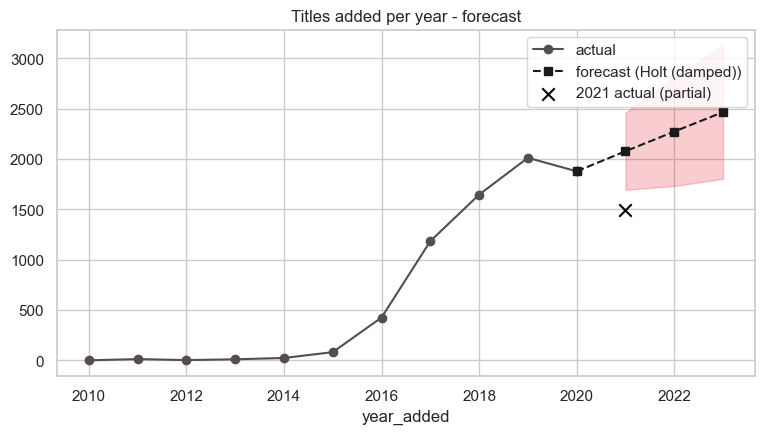

In [11]:
H = 3  # 2021 (full-year estimate), 2022, 2023
fc = np.clip(MODELS[best](ts.values, H), 0, None)
rm = ev.loc[best, 'RMSE']
fcast = pd.DataFrame({'forecast': fc.round(0), 'low': np.clip(fc - 1.28 * rm * np.sqrt(np.arange(1, H + 1)), 0, None).round(0),
                      'high': (fc + 1.28 * rm * np.sqrt(np.arange(1, H + 1))).round(0)}, index=[2021, 2022, 2023])
partial_2021 = int((df['year_added'] == 2021).sum())
print(fcast); print('2021 actual so far (to 25 Sep):', partial_2021)
ax = ts.plot(marker='o', color=GREY, figsize=(9, 4.5), label='actual')
ax.plot([2020, 2021, 2022, 2023], [ts.iloc[-1], *fc], 'k--s', label=f'forecast ({best})')
ax.fill_between(fcast.index, fcast['low'], fcast['high'], color=RED, alpha=.2)
ax.scatter([2021], [partial_2021], marker='x', color='black', s=80, label='2021 actual (partial)')
ax.set_title('Titles added per year - forecast'); ax.legend(); plt.show()

## Step 3 – Create interactive visualizations

The interactive dashboard is a standalone HTML page (filters for content type and year range; KPIs, additions, countries, genres, audience mix, model results and forecast). The cell below exports the aggregated numbers it uses, so the dashboard and this notebook always agree.

In [12]:
yrs = list(range(2014, 2022))
cube = {}
dd = df[df['year_added'].isin(yrs)].assign(genres=gl)
for (t, yr), grp in dd.groupby(['type', 'year_added']):
    ctry = grp.loc[grp['primary_country'] != 'Unknown', 'primary_country'].value_counts()
    gen = grp['genres'].explode().value_counts()
    cube[f'{t}|{yr}'] = {'n': int(len(grp)),
                         'c': {k: int(v) for k, v in ctry.items() if k in set(df['primary_country'].value_counts().head(12).index)},
                         'g': {k: int(v) for k, v in gen.items() if k in set(gc.index.map(lambda x: x.replace('_', ' ').title())) or True},
                         'a': {k: int(v) for k, v in grp['audience'].astype(str).value_counts().items()}}
# keep only the 12 most common genres overall (less data to ship)
top_g = gdf['genres'].value_counts().head(12).index.tolist()
for v in cube.values():
    v['g'] = {k: x for k, x in v['g'].items() if k in top_g}

dash = {'years': yrs, 'cube': cube, 'kpi': {k: round(float(v), 1) for k, v in kpi.items()},
        'models': {'audience': {'acc': round(acc, 3), 'f1': round(f1m, 3), 'cv': round(cv, 3), 'baseline': round(base, 3)}},
        'forecast': {'hist': {int(k): int(v) for k, v in ts.items()}, 'fc': {int(k): int(v) for k, v in fcast['forecast'].items()},
                     'low': {int(k): int(v) for k, v in fcast['low'].items()}, 'high': {int(k): int(v) for k, v in fcast['high'].items()},
                     'partial2021': partial_2021, 'model': best}}
json.dump(dash, open('dashboard_data.json', 'w'))
print('exported', len(json.dumps(dash)) // 1024, 'KB |', len(cube), 'cells | genres:', top_g)

exported 7 KB | 16 cells | genres: ['International', 'Dramas', 'Comedies', 'Action Adventure', 'Romantic', 'Documentaries', 'Independent', 'Children Family', 'Thrillers', 'Crime', 'Kids', 'Horror']


## Step 4 – Generate business recommendations

> **Scope note:** the dataset has no viewing, cost or revenue data, so these are *catalogue-strategy* recommendations backed by what was added, from where and for whom - not claims about what viewers prefer.

| # | Finding (evidence) | Recommendation |
|---|---|---|
| 1 | **Volume growth has plateaued.** Titles added per year peaked at 2,013 in 2019, fell 6.7% in 2020 (1,879), and 2021 is on pace for ~2,000 (1,498 by 25 Sep). Forecast (damped Holt): ~2,060 for 2021, ~2,240–2,420 for 2022–23, but with a wide range (≈1,700–3,060). | Plan for a **flat-to-modest growth band of ~1,700–2,400 titles/year**. Stop using volume as the success metric; add quality metrics (completion, retention) once viewing data is available. |
| 2 | **The catalogue is now majority international.** Non-US share of added titles rose from ~21% (2014) to 58–68% since 2017. Since 2019 the biggest non-US sources are India, UK, Pakistan, Japan, Canada, South Korea and France. Comparing 2019-20 with 2017-18 (total additions +37%): Japan +87%, France +52%, South Korea +46%, but **India −15%**. | **Keep investing in Japan, South Korea and France** (fast-growing sources). **Review the India pipeline** - the largest non-US source is shrinking while the catalogue grows. |
| 3 | **Series are growing but mostly short-lived.** TV share of additions rose from 25% (2018) to ~34% (2021), yet **67% of TV shows have just one season - and still 70% of shows released in 2016 or earlier**, so it isn't only because they're new. | Use viewing data to separate *planned* limited series from *cancelled* shows; prioritise renewals / multi-season franchises where retention supports it. |
| 4 | **Genre mix is shifting.** From 2017 to 2020, Comedies gained 8.7 percentage points of additions while Documentaries lost 11.1 pp. (A 2016 base gives a different picture - 2016 was a small, atypical year - so treat this as indicative.) | Check whether the shift is deliberate or driven by licensing availability, and keep a **deliberate genre portfolio** rather than drifting. |
| 5 | **Family content is steady but dipped.** Kids + Older Kids made up ~23% of titles overall; their share of additions fell to ~21-22% in 2018-19 and recovered to ~23-24% in 2020-21. Adults content is stable at ~45-47%. | Maintain a **~20-25% family floor**; the audience model identifies Kids content best (F1 0.82), so automate kid-safe tagging and parental-control buckets. |
| 6 | **Metadata gaps limit analytics and tagging.** 29% of titles have no director and 82 titles have no rating. The audience classifier (Random Forest) reaches ~64% accuracy vs a 46% baseline (macro-F1 0.62). It suggests 59 / 15 / 7 / 1 Adults / Teens / Older Kids / Kids for the 82 unrated titles. | Use the model as a **triage tool with human review** (it is weakest on Teens and Older Kids), and invest in metadata completeness. The Adults-heavy suggestions should be checked before use. |
| 7 | **Release timing is concentrated.** 28% of additions land on a Friday; Oct-Dec each account for ~10% of additions vs ~7-8% in other months. | Align marketing and promotion calendars to the Friday / Q4 peaks, and test whether spreading releases reduces competition between titles. |

**Data to collect next:** viewing hours and completion, production / licensing cost, subscriber retention by title, plot descriptions and cast - these would turn the catalogue insights above into true performance recommendations.


## Step 5 – Present findings in a professional report
See the accompanying **report document** (executive summary, method, findings, model results, recommendations, risks) and the **interactive dashboard** page. Both use the exact numbers computed in this notebook.